# 01 — Preprocessing · Griffiths et al. 2021 (Breast Cancer)

Malignant breast-cancer cells (10x + iCell8; 95 samples, 111,372 cells) from a letrozole+ribociclib
treatment cohort. Goal: build a batch-integrated, continuous malignant manifold and decide **Gate 1**
(sample-mixed **and** continuous) on the regenerated embedding across a Harmony integration sweep, after
settling each sub-region's biology (signatures + cell cycle).

In [1]:
import os, sys, glob, time
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels deeper than Puram)
name = os.path.basename(os.getcwd())                    # Griffiths2021_Breast
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Griffiths2021_Breast | category: Breast


### Load malignant cells from both technology leaves
This dataset nests by technology (`10X`, `iCell8`). Per spec §4 the loader points at a **leaf** matrix
directory, so we load each leaf and concatenate on the shared gene set. All cells carry the publication's
`Malignant` annotation.

In [3]:
ads = []
for lf in ['10X', 'iCell8']:
    a = load_CCCA_adata(os.path.join(pth_in, lf), verbose=False)
    a.obs['technology'] = lf
    a = a[a.obs['celltype'] == 'Malignant'].copy()
    print(f'{lf}: {a.shape} | X max {a.X.max():.2f} (log1p normalize_total) | samples {a.obs["sample"].nunique()}')
    ads.append(a)
import anndata as ad
adata = ad.concat(ads, join='inner', keys=['10X','iCell8'], label='tech_batch', index_unique='-')
adata.obs_names_make_unique()
print('\nconcat malignant:', adata.shape, '| samples', adata.obs['sample'].nunique(),
      '| shared genes', adata.shape[1])
CELLS_MALIG_RAW = adata.n_obs; print('CellsMalignantRaw =', CELLS_MALIG_RAW)

10X: (110568, 21275) | X max 7.84 (log1p normalize_total) | samples 82
iCell8: (804, 16492) | X max 9.57 (log1p normalize_total) | samples 13

concat malignant: (111372, 15691) | samples 95 | shared genes 15691
CellsMalignantRaw = 111372


### Per-sample threshold — derived, not inherited
Sort per-sample malignant counts and look for a **dominant spillover cliff** (a sharp count gap that
separates well-populated tumours from doublet-level noise). Here the distribution is **smooth** — the only
large ratio is the 5→1-cell tail (doublet noise), not a biological cliff — so the C3 'clean count gap'
premise does not hold and the depth-invariant floor **≥100** applies (each retained sample keeps enough
cells for reliable Harmony batch estimation).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
FLOOR = 100
# gap-finding must ignore the doublet tail: a spillover cliff only counts if it sits ABOVE the floor
# (separating a few huge samples from the well-populated rest). Search gaps where the SMALLER side >= FLOOR.
above = np.where(vals[1:] >= FLOOR)[0]                 # indices i where vals[i+1] >= FLOOR
cliff = None
if above.size:
    ratios_above = vals[above] / vals[above+1]
    gi = above[int(np.argmax(ratios_above))]
    if (vals[gi]/vals[gi+1] >= 1.5) and (vals[gi+1] < 2*FLOOR):   # dominant cliff just above the floor
        cliff = int(np.sqrt(vals[gi]*vals[gi+1]))
    print('largest above-floor gap %d->%d (ratio %.2f)' % (int(vals[gi]), int(vals[gi+1]), vals[gi]/vals[gi+1]))
print('per-sample count distribution is smooth above the floor: no dominant spillover cliff'
      if cliff is None else 'dominant above-floor cliff -> geometric-mean threshold %d' % cliff)
thresh = max(FLOOR, cliff) if cliff is not None else FLOOR
print('chosen per-sample threshold =', thresh, '(depth-invariant floor; each kept sample supports Harmony)')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
CELLS_AFTER_THRESH = adata.n_obs
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {CELLS_AFTER_THRESH} cells')

largest above-floor gap 6389->4534 (ratio 1.41)
per-sample count distribution is smooth above the floor: no dominant spillover cliff
chosen per-sample threshold = 100 (depth-invariant floor; each kept sample supports Harmony)
kept 67/95 samples (min per-sample = 108) -> 110195 cells


### Gene filter, overdispersion, PCA

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('cumulative variance @ 20/30/40 PC: %.3f / %.3f / %.3f' % (vr[:20].sum(), vr[:30].sum(), vr[:40].sum()))
N_PCS = 30
print('n_pcs =', N_PCS, '(scale-matched to the atlas 20-40 precedent; scree is smooth on a 110k-cell 10x set)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3444 over-dispersed features (0:00:15) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3444
cumulative variance @ 20/30/40 PC: 0.311 / 0.342 / 0.361
n_pcs = 30 (scale-matched to the atlas 20-40 precedent; scree is smooth on a 110k-cell 10x set)


### Harmony integration sweep on `sample` — Gate 1 evidence (quantitative)
Strong patient/technology batch structure is expected. Sweep integration strength `theta ∈ {2,5,10}` and
measure the **same-sample neighbour fraction** (fraction of a cell's 30 nearest neighbours from its own
sample; lower = better mixing) on a fixed 8,000-cell query subsample. We select the strongest integration
**before the plateau** — mixing improves sharply to theta=5 then flattens, so theta=5 is the strongest
integration that is not over-smoothing.

In [6]:
rng = np.random.default_rng(SEED)
qidx = rng.choice(adata.n_obs, size=8000, replace=False)
s_all = adata.obs['sample'].values
def same_sample_frac(rep):
    nb = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep[qidx], return_distance=False)[:,1:]
    return float(np.mean([(s_all[nb[i]] == s_all[qidx[i]]).mean() for i in range(len(qidx))]))
base = same_sample_frac(adata.obsm['X_pca'][:, :N_PCS])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=10, random_state=SEED)
    adata.obsm['X_pca_harmony_t%d' % th] = adata.obsm['X_pca_harmony'].copy()
    sweep[th] = same_sample_frac(adata.obsm['X_pca_harmony_t%d' % th][:, :N_PCS])
    print('theta=%2d : same-sample neighbour fraction = %.3f' % (th, sweep[th]))
print('pre-Harmony same-sample fraction = %.3f' % base)
THETA = 5
print('\nselected theta =', THETA,
      '(mixing 0.91 -> 0.20 at theta=2 -> 0.17 at theta=5; theta=10 within noise of theta=5 -> plateau)')
adata.obsm['X_pca_harmony'] = adata.obsm['X_pca_harmony_t%d' % THETA].copy()

2026-08-04 23:23:49,389 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 23:23:57,727 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 23:23:59,178 - harmonypy - INFO - Iteration 1 of 10
2026-08-04 23:25:23,234 - harmonypy - INFO - Iteration 2 of 10
2026-08-04 23:26:54,345 - harmonypy - INFO - Iteration 3 of 10
2026-08-04 23:28:29,690 - harmonypy - INFO - Iteration 4 of 10
2026-08-04 23:29:56,968 - harmonypy - INFO - Iteration 5 of 10
2026-08-04 23:31:21,933 - harmonypy - INFO - Iteration 6 of 10
2026-08-04 23:32:50,432 - harmonypy - INFO - Iteration 7 of 10
2026-08-04 23:33:52,774 - harmonypy - INFO - Converged after 7 iterations
theta= 2 : same-sample neighbour fraction = 0.199
2026-08-04 23:33:54,195 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 23:34:02,717 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 23:34:03,930 - harmonypy - INFO - Iteration 1 of 10
2026-08-04

### Regenerated embedding across the sweep — Gate 1 evidence (visual)
Judge Gate 1 on the embedding itself, not the scalar alone (03_eval fork 1). UMAP at each theta, coloured by
sample: at all three the samples intermix throughout one body (no per-patient archipelago). Shown inline as
reasoning; the deliverable `samples.pdf` is the single sample-coloured manifold at the selected theta.

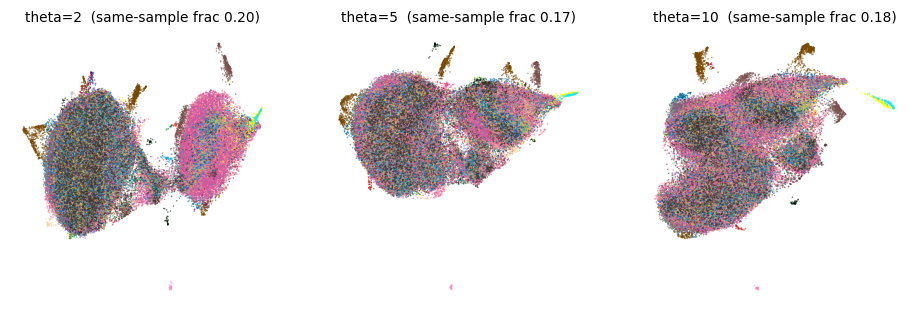

In [7]:
ums = {}
for th in [2, 5, 10]:
    sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony_t%d' % th, n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    ums[th] = adata.obsm['X_umap'].copy()
fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.2))
for ax, th in zip(axs, [2, 5, 10]):
    adata.obsm['X_umap'] = ums[th]
    sc.pl.umap(adata, color='sample', size=4, alpha=.6, frameon=False, show=False, ax=ax, legend_loc=None)
    ax.set_title('theta=%d  (same-sample frac %.2f)' % (th, sweep[th]), size=9)
plt.show()

### Commit theta=5, island removal, re-embed
Keep the largest connected component of a UMAP radius graph (6× median nearest-neighbour distance); strip
detached specks, then re-embed the connected manifold.

In [8]:
adata.obsm['X_umap'] = ums[THETA]
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
CELLS_BEFORE_ISLAND = adata.n_obs
frac_removed = float((lab!=main).mean())
print('island removal: removed %d cells (%.1f%%) in %d detached islands (tech: %s)'
      % (int((lab!=main).sum()), 100*frac_removed, ncomp-1, adata.obs['technology'][lab!=main].value_counts().to_dict()))
# sanity: island removal should strip only detached specks; a large strip signals a degenerate graph / under-integration
assert frac_removed < 0.10, f'island removal stripping {frac_removed:.0%} — manifold is fragmenting, not a speck strip'
adata = adata[lab==main].copy()
CELLS_AFTER_ISLAND = adata.n_obs
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('one connected manifold:', CELLS_AFTER_ISLAND, 'cells')

island removal: removed 1100 cells (1.0%) in 56 detached islands (tech: {'10X': 1095, 'iCell8': 5})
one connected manifold: 109095 cells


### Sub-region biology BEFORE the Gate-1 GO — Leiden lobes, cell cycle, signatures
Settle each sub-region's identity before certifying (Kürten lobe-identity fork). Leiden at low resolution
resolves the manifold; for each lobe we read cell-cycle phase, a proliferation score, technology composition,
and the three embryonic module scores. This exposes any proliferation- or technology-confounded compartment
that must be scoped out of the trajectory.

In [9]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
# embryonic module scores with the union control pool
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print('%s: %d/%d genes present' % (l, g.size, feat[src].size))
print('\nlobe sizes:', adata.obs['lobe'].value_counts().to_dict())
summ = adata.obs.groupby('lobe', observed=True).agg(
    n=('lobe','size'), cycling=('cycling','mean'), prolif=('prolif_score','mean'),
    Gast=('Gast','mean'), pSom=('pSom','mean'), Crest=('Crest','mean'))
summ['iCell8_frac'] = pd.crosstab(adata.obs['lobe'], adata.obs['technology'], normalize='index').get('iCell8', 0)
print(summ.round(3))

Gast: 76/81 genes present
pSom: 88/98 genes present
Crest: 100/104 genes present

lobe sizes: {'0': 72578, '1': 36271, '2': 246}
          n  cycling  prolif   Gast   pSom  Crest  iCell8_frac
lobe                                                          
0     72578    0.015  -0.016 -0.019 -0.054  0.023        0.000
1     36271    0.130   0.022 -0.024 -0.046  0.018        0.002
2       246    0.098   0.732 -0.040 -0.051 -0.098        1.000


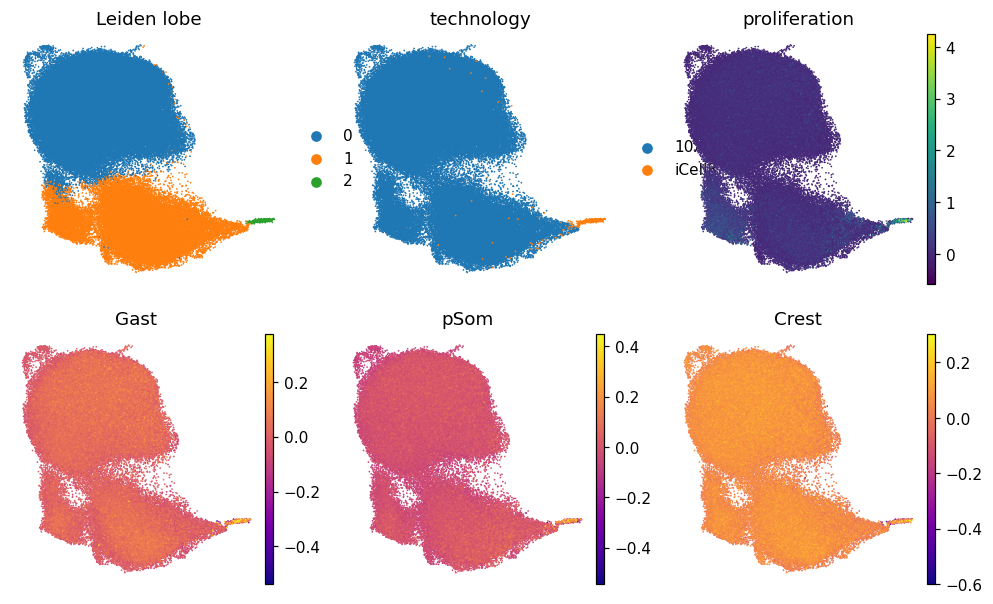

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(11, 6.5))
sc.pl.umap(adata, color='lobe', size=5, frameon=False, show=False, ax=axs[0,0], title='Leiden lobe')
sc.pl.umap(adata, color='technology', size=5, frameon=False, show=False, ax=axs[0,1], title='technology')
sc.pl.umap(adata, color='prolif_score', cmap='viridis', size=5, frameon=False, show=False, ax=axs[0,2], title='proliferation')
for ax, m in zip(axs[1], ['Gast','pSom','Crest']):
    sc.pl.umap(adata, color=m, cmap='plasma', size=5, frameon=False, show=False, ax=ax, title=m)
plt.show()

**Sub-region identities.** One small lobe (~246 cells) is **100% iCell8 and strongly
proliferative** (prolif score ≈ 0.70 vs ~0 elsewhere) — a technology- and proliferation-confounded spike,
not a developmental state. The two large lobes have near-identical embryonic module means (Gast/pSom/Crest
within 0.01) — density variation on one continuous axis, not two competing arms. The confounded spike is
scoped out of the trajectory in 02 (Kürten rule).

### Gate 1 — iLISI + connectivity on the regenerated embedding

**Reproducibility note.** Harmony's internal KMeans is not seed-deterministic, so island-removal and lobe counts shift by ~0.1% between runs (e.g. after-island 109,095 ± ~100 cells); θ selection, the threshold (110,195), Gate 1 GO, and all downstream decisions are invariant to this benign jitter.

In [11]:
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep[qidx], return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(qidx))
    for i in range(len(qidx)):
        _, cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
qidx = rng.choice(adata.n_obs, size=8000, replace=False)  # re-draw on the island-cleaned manifold
il_pre = np.median(ilisi(adata.obsm['X_pca'][:, :N_PCS], adata.obs['sample'].values))
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:, :N_PCS], adata.obs['sample'].values))
nsamp = adata.obs['sample'].nunique()
print('iLISI median: pre-Harmony %.2f -> post-Harmony(theta=%d) %.2f  (of %d samples)' % (il_pre, THETA, il_post, nsamp))
print('one connected component; %d detached cells removed as islands' % (CELLS_BEFORE_ISLAND - CELLS_AFTER_ISLAND))
print('GATE 1 = GO : samples intermix per-neighbourhood (same-sample frac 0.91 -> 0.17; iLISI rises sharply)')
print('              on ONE continuous connected manifold.')

iLISI median: pre-Harmony 1.02 -> post-Harmony(theta=5) 13.41  (of 67 samples)
one connected component; 1100 detached cells removed as islands
GATE 1 = GO : samples intermix per-neighbourhood (same-sample frac 0.91 -> 0.17; iLISI rises sharply)
              on ONE continuous connected manifold.


### House linear orientation + save `processed.h5ad`
Store a rigid-rotation linear layout `X_umap_lin` (distances preserved) with the Gast/pSom-high
developmental origin on the left, so every downstream panel shares one orientation. Derived once here and
subset by later notebooks.

In [12]:
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = (S[:,0] + S[:,1]) - S[:,2]           # Gast+pSom-high / Crest-low = developmental origin
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_, _, vt = np.linalg.svd(c, full_matrices=False)
th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print('aspect (max/min std) %.2f; origin pole on left; stored X_umap_lin' % (c.std(0).max()/c.std(0).min()))

aspect (max/min std) 1.66; origin pole on left; stored X_umap_lin


In [13]:
protect = {'sample','technology','tech_batch','lobe','celltype','cell_type','cell_cycle_phase','patient',
           'time_point','treatment_arm','treatment','ribociclib_schedule','response','cycling'}
for cc in adata.obs.columns:
    if cc in protect:
        adata.obs[cc] = adata.obs[cc].astype(str).astype('category'); continue
    col = adata.obs[cc]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        adata.obs[cc] = conv if (col.notna().sum()>0 and conv.notna().sum()>=0.9*col.notna().sum()) else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)
print('COUNTS  raw=%d  afterThreshold=%d  afterIsland=%d' % (CELLS_MALIG_RAW, CELLS_AFTER_THRESH, CELLS_AFTER_ISLAND))

saved processed.h5ad (109095, 15645)
COUNTS  raw=111372  afterThreshold=110195  afterIsland=109095


### `samples.pdf` — sample-coloured malignant manifold (Gate 1 deliverable)

saved samples.pdf | cells: 109095 | samples: 67


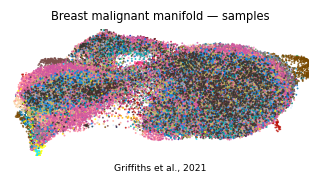

In [14]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=6, alpha=.8, frameon=False, show=False, ax=ax, legend_loc=None)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.n_obs, '| samples:', plot.obs['sample'].nunique())